# Long-budget learning order — analysis

Compare the **9,000-update constant versus cosine learning-rate studies** using the same five seeds and four curricula. This analysis separates the effects of *task ordering* from the effects of *optimization time* without training a new model.

**Report outputs:** figures and CSV summaries are saved together in `outputs/medium_world/experiments/longer_budget/`. The input training results remain in `constant/` and `cosine/`.

In [1]:
from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = Path().cwd().parent.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

BASE = PROJECT_ROOT / 'outputs/medium_world/experiments/longer_budget'
paths = {
    'constant': BASE / 'constant/schedule_comparison.json',
    'cosine': BASE / 'cosine/schedule_comparison.json'
}
reports = {name: json.loads(path.read_text(encoding='utf-8'))
           for name, path in paths.items()}
SCHEDULES = ('mixed', 'staged', 'staged_rehearsal', 'reverse')
TASKS = ('color', 'shape', 'conjunction', 'pair')
print({name: (len(report['runs']), sorted({r['seed'] for r in report['runs']}))
       for name, report in reports.items()})

OUTPUT_DIR = BASE

def save_figure(fig, filename):
    fig.savefig(OUTPUT_DIR / f'{filename}.png', dpi=300,
                bbox_inches='tight', facecolor='white')

{'constant': (20, [42, 43, 44, 45, 46]), 'cosine': (20, [42, 43, 44, 45, 46])}


## 1. What is controlled?

Each model receives exactly **45 presentations per training example**, totaling 450,000 presentations and 9,000 updates. The `constant/` and `cosine/` subdirectories hold the two experiments. Their training records are read together, while their analysis results are saved in the shared `analysis/` directory. Schedule comparisons within one LR policy control the learning-rate trajectory; constant-versus-cosine comparisons test a separate intervention.

In [2]:
protocol = pd.DataFrame([{
    'lr_policy': name, 'seed': r['seed'], 'schedule': r['schedule'],
    'updates': r['steps_run'],
    'total_presentations': r['phase_plan']['total_presentations'],
    'per_example': r['phase_plan']['repetitions_per_example'],
    **r['phase_plan']['counts_by_template']
} for name, report in reports.items() for r in report['runs']])
display(protocol.groupby(['lr_policy', 'schedule'])
        [['updates', 'total_presentations', 'per_example']].agg(['min', 'max']))

updates       total_presentations          \
                               min   max                 min     max   
lr_policy schedule                                                     
constant  mixed               9000  9000              450000  450000   
          reverse             9000  9000              450000  450000   
          staged              9000  9000              450000  450000   
          staged_rehearsal    9000  9000              450000  450000   
cosine    mixed               9000  9000              450000  450000   
          reverse             9000  9000              450000  450000   
          staged              9000  9000              450000  450000   
          staged_rehearsal    9000  9000              450000  450000   

                           per_example      
                                   min max  
lr_policy schedule                          
constant  mixed                     45  45  
          reverse                   45  45  
          staged                    45  45  
          staged_rehearsal          45  45  
cosine    mixed                     45  45  
          reverse                   45  45  
          staged                    45  45  
          staged_rehearsal          45  45

## 2. Final accuracy, OOD transfer, and binding efficiency

The main outcome is final ID **same-object binding**. OOD accuracy and OOD cross-entropy test unseen combinations. Binding AULC summarizes the entire learning trajectory, including the period before staged curricula begin binding training.

In [3]:
rows = []
for name, report in reports.items():
    for r in report['runs']:
        f = r['final']
        rows.append({
            'lr_policy': name, 'seed': r['seed'], 'schedule': r['schedule'],
            'overall_id': 100 * f['id_dev']['accuracy'],
            'ood_pair': 100 * f['ood_dev']['by_template']['pair'],
            'ood_bce': f['ood_dev']['loss'],
            'pair_aulc': 100 * r['id_pair_aulc'],
            **{task: 100 * f['id_dev']['by_template'][task] for task in TASKS}
        })
final = pd.DataFrame(rows)
metrics = ['overall_id', 'pair', 'shape', 'ood_pair', 'ood_bce', 'pair_aulc']
final.to_csv(BASE / 'final_by_seed.csv', index=False)
display(final.groupby(['lr_policy', 'schedule'])[metrics]
        .agg(['mean', 'std']).round(2))

overall_id         pair        shape        \
                                 mean   std   mean   std   mean   std   
lr_policy schedule                                                      
constant  mixed                 76.66  0.86  61.02  2.80  67.11  2.58   
          reverse               74.65  1.38  56.41  1.42  64.92  1.98   
          staged                77.11  1.64  62.19  5.41  66.48  2.06   
          staged_rehearsal      77.48  1.40  62.81  2.30  67.19  2.80   
cosine    mixed                 75.21  1.59  59.06  2.90  65.08  0.94   
          reverse               73.40  1.61  56.41  0.59  62.58  2.40   
          staged                75.27  1.86  56.64  5.28  64.69  2.74   
          staged_rehearsal      75.35  1.41  56.88  2.53  65.16  2.78   

                           ood_pair       ood_bce       pair_aulc        
                               mean   std    mean   std      mean   std  
lr_policy schedule                                                       
constant  mixed               56.20  2.84    0.74  0.08     56.89  2.01  
          reverse             52.60  2.53    0.77  0.05     52.78  1.12  
          staged              56.05  3.18    0.79  0.03     54.87  1.12  
          staged_rehearsal    56.35  3.55    0.79  0.06     55.20  0.85  
cosine    mixed               54.70  3.37    0.73  0.03     56.12  2.47  
          reverse             53.80  3.80    0.80  0.07     52.83  1.46  
          staged              53.05  4.96    0.75  0.03     53.18  1.51  
          staged_rehearsal    53.65  2.90    0.75  0.02     53.44  1.27

## Final binding versus LR policy — report figure

This comparison holds curriculum and seed fixed while changing the learning-rate trajectory. The two columns distinguish familiar ID binding from withheld OOD combinations.

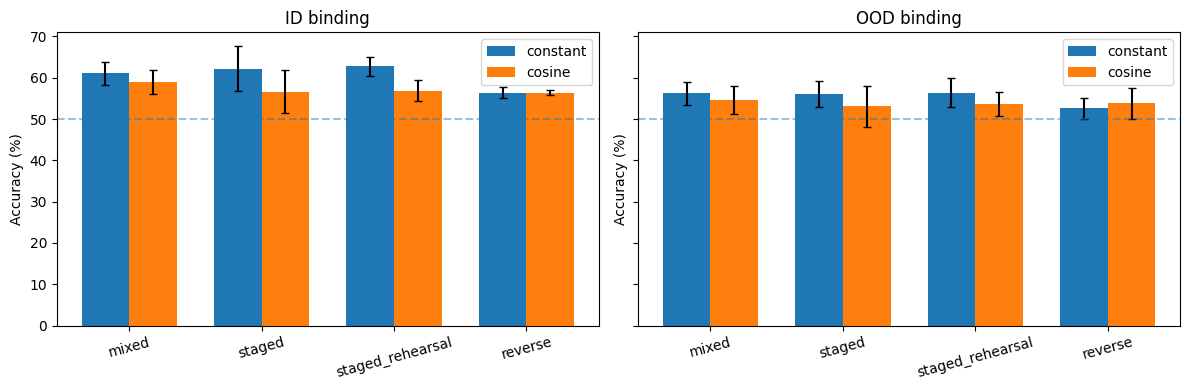

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
x = np.arange(len(SCHEDULES))
width = 0.36
for ax, metric, title in zip(axes, ('pair', 'ood_pair'),
                              ('ID binding', 'OOD binding')):
    for offset, lr_policy in zip((-.5, .5), reports):
        part = final[final.lr_policy == lr_policy].groupby('schedule')[metric]
        means = part.mean().reindex(SCHEDULES)
        stds = part.std().reindex(SCHEDULES)
        ax.bar(x + offset*width, means, width, yerr=stds, capsize=3,
               label=lr_policy)
    ax.axhline(50, linestyle='--', alpha=.45)
    ax.set(xticks=x, xticklabels=SCHEDULES,
           title=title, ylabel='Accuracy (%)')
    ax.tick_params(axis='x', rotation=15)
    ax.legend()
plt.tight_layout()
save_figure(fig, 'final_binding_by_lr_policy')
plt.show()

## 3. Paired effects of schedule and learning rate

For a seed-matched comparison, $\Delta_s=A_{s,1}-A_{s,2}$. We compare curricula under the **same LR policy** and then compare constant versus cosine **for each curriculum**. Five-seed means and wins are descriptive, not conclusive statistical evidence.

In [5]:
comparisons = (('staged_rehearsal', 'staged'), ('staged_rehearsal', 'mixed'),
               ('staged', 'mixed'), ('reverse', 'mixed'))
results = []
for lr_policy in reports:
    part = final[final.lr_policy == lr_policy]
    for first, second in comparisons:
        for metric in ('pair', 'pair_aulc', 'ood_pair', 'overall_id'):
            pivot = part.pivot(index='seed', columns='schedule', values=metric)
            delta = pivot[first] - pivot[second]
            results.append({'lr_policy': lr_policy, 'contrast': first + ' − ' + second,
                            'metric': metric, 'mean_pp': delta.mean(),
                            'sd_pp': delta.std(), 'wins': (delta > 0).sum()})
paired = pd.DataFrame(results)
paired.to_csv(BASE / 'paired_curricula.csv', index=False)
display(paired.round(2))

,lr_policy,contrast,metric,mean_pp,sd_pp,wins
0,constant,staged_rehearsal − staged,pair,0.62,3.53,2
1,constant,staged_rehearsal − staged,pair_aulc,0.33,0.63,4
2,constant,staged_rehearsal − staged,ood_pair,0.30,1.32,2
3,constant,staged_rehearsal − staged,overall_id,0.37,1.05,3
4,constant,staged_rehearsal − mixed,pair,1.80,1.06,4
5,constant,staged_rehearsal − mixed,pair_aulc,-1.68,1.52,1
6,constant,staged_rehearsal − mixed,ood_pair,0.15,5.23,2
7,constant,staged_rehearsal − mixed,overall_id,0.82,1.06,4
8,constant,staged − mixed,pair,1.17,3.63,3
9,constant,staged − mixed,pair_aulc,-2.02,1.46,1


In [6]:
cross_lr = []
for schedule in SCHEDULES:
    part = final[final.schedule == schedule]
    for metric in ('pair', 'pair_aulc', 'ood_pair', 'overall_id', 'ood_bce'):
        pivot = part.pivot(index='seed', columns='lr_policy', values=metric)
        delta = pivot['constant'] - pivot['cosine']
        cross_lr.append({'schedule': schedule, 'metric': metric,
                         'constant_minus_cosine': delta.mean(),
                         'wins': (delta > 0).sum()})
cross_lr = pd.DataFrame(cross_lr)
cross_lr.to_csv(BASE / 'constant_minus_cosine.csv', index=False)
display(cross_lr.round(3))

,schedule,metric,constant_minus_cosine,wins
0,mixed,pair,1.953,4
1,mixed,pair_aulc,0.767,4
2,mixed,ood_pair,1.500,3
3,mixed,overall_id,1.445,5
4,mixed,ood_bce,0.011,2
5,staged,pair,5.547,4
6,staged,pair_aulc,1.696,5
7,staged,ood_pair,3.000,4
8,staged,overall_id,1.836,5
9,staged,ood_bce,0.040,5


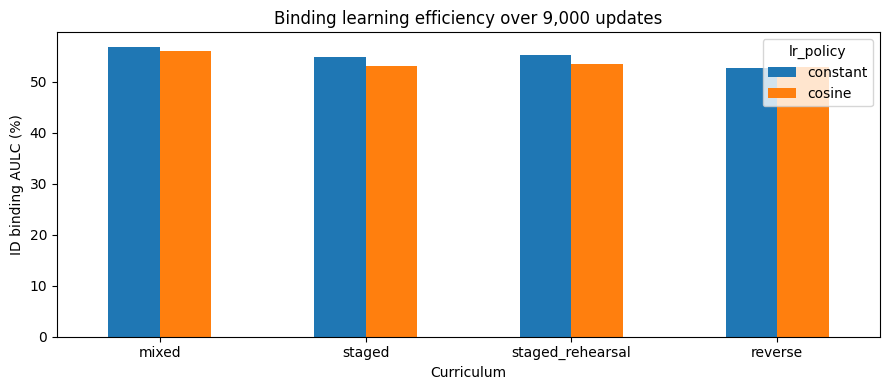

In [7]:
pivot = final.groupby(['schedule', 'lr_policy'])['pair_aulc'].mean().unstack()
pivot = pivot.reindex(SCHEDULES)
fig, ax = plt.subplots(figsize=(9, 4))
pivot.plot.bar(ax=ax, rot=0)
ax.set(title='Binding learning efficiency over 9,000 updates',
       xlabel='Curriculum', ylabel='ID binding AULC (%)')
plt.tight_layout()
save_figure(fig, 'binding_learning_efficiency')
plt.show()

## 4. Learning curves

For binding accuracy \(A(t)\), the area under the learning curve is

$$\mathrm{AULC}=\frac{1}{T}\int_0^T A(t)\,dt.$$

It measures performance averaged over **all optimizer updates**. It should not be interpreted as improvement per binding example, because staged and mixed schedules introduce the task at different times.

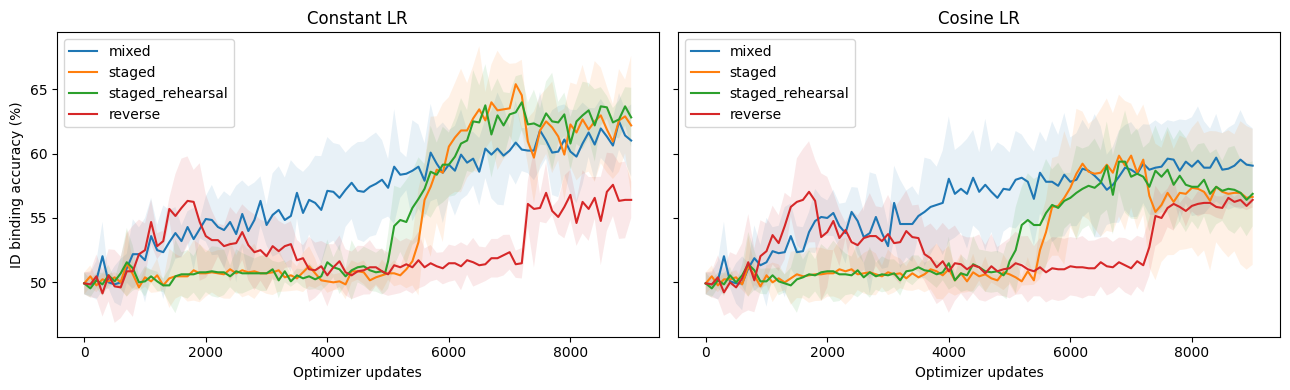

In [8]:
history = pd.DataFrame([{
    'lr_policy': name, 'seed': r['seed'], 'schedule': r['schedule'],
    'step': h['step'], 'phase': h['phase'], 'lr': h['lr'],
    **{task: 100 * h['id_dev']['by_template'][task] for task in TASKS}
} for name, report in reports.items() for r in report['runs'] for h in r['history']])
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, lr_policy in zip(axes, reports):
    part = history[history.lr_policy == lr_policy]
    for schedule in SCHEDULES:
        curve = part[part.schedule == schedule].groupby('step')['pair'].agg(['mean', 'std'])
        ax.plot(curve.index, curve['mean'], label=schedule)
        ax.fill_between(curve.index, curve['mean'] - curve['std'],
                        curve['mean'] + curve['std'], alpha=.10)
    ax.set(title=lr_policy.title() + ' LR', xlabel='Optimizer updates')
    ax.legend()
axes[0].set_ylabel('ID binding accuracy (%)')
plt.tight_layout()
save_figure(fig, 'id_binding_learning_curves')
plt.show()

## 5. Why constant and cosine update differently

Both studies use AdamW. The difference is the *externally chosen step size*. Constant LR holds $\eta_t=10^{-4}$; cosine LR follows

$$\eta_t=\eta_{\min}+\frac{\eta_{\max}-\eta_{\min}}{2}
\left[1+\cos\left(\pi\frac{t-1}{T-1}\right)\right].$$

Here $\eta_{\max}=10^{-4}$, $\eta_{\min}=10^{-5}$, and $T=9000$. The earlier ReduceLROnPlateau experiments lowered LR in response to validation loss; this cosine schedule does **not** react to validation and does **not** reset at stage changes.

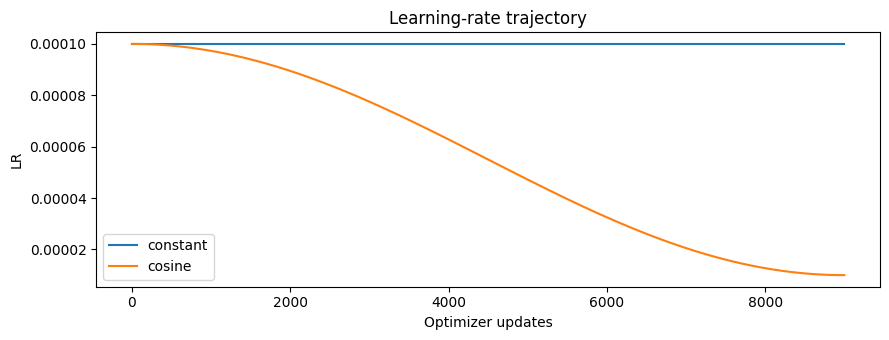

In [9]:
fig, ax = plt.subplots(figsize=(9, 3.5))
for name in reports:
    series = history[(history.lr_policy == name) &
                     (history.seed == 42) & (history.schedule == 'mixed')]
    ax.plot(series.step, series.lr, label=name)
ax.set(title='Learning-rate trajectory', xlabel='Optimizer updates', ylabel='LR')
ax.legend()
plt.tight_layout()
save_figure(fig, 'learning_rate_trajectories')
plt.show()

## 6. Retention when task mixtures change

A transition may temporarily reduce accuracy on earlier skills. We compare consecutive evaluation checkpoints that straddle each stage change (normally 100 updates apart). These descriptive changes combine a new task mixture with continued optimization.

In [10]:
changes = []
for name, report in reports.items():
    for r in report['runs']:
        for before, after in zip(r['history'], r['history'][1:]):
            if before['phase'] == after['phase']:
                continue
            changes.append({
                'lr_policy': name, 'schedule': r['schedule'], 'seed': r['seed'],
                'transition': before['phase'] + ' → ' + after['phase'],
                **{task: 100 * (after['id_dev']['by_template'][task] -
                                before['id_dev']['by_template'][task]) for task in TASKS}
            })
changes = pd.DataFrame(changes)
changes.to_csv(BASE / 'transition_deltas.csv', index=False)
display(changes.groupby(['lr_policy', 'schedule', 'transition'])
        [list(TASKS)].mean().round(2))

color  shape  \
lr_policy schedule         transition                                
constant  mixed            initial → mixed             0.94   0.39   
                           mixed → common_mixed        0.16   1.64   
          reverse          attributes → common_mixed  -0.23  -0.86   
                           binding → conjunction       8.67   2.58   
                           conjunction → attributes   11.95   0.47   
                           initial → binding          -0.94   0.08   
          staged           attributes → conjunction   -9.61  -5.70   
                           binding → common_mixed     16.33   7.73   
                           conjunction → binding      -6.17  -4.92   
                           initial → attributes        0.31  -0.16   
          staged_rehearsal attributes → conjunction   -1.33  -1.56   
                           binding → common_mixed      0.62   0.39   
                           conjunction → binding      -0.47  -0.31   
                           initial → attributes       -0.23   0.47   
cosine    mixed            initial → mixed             0.94   0.39   
                           mixed → common_mixed       -0.16   0.31   
          reverse          attributes → common_mixed  -1.17  -2.34   
                           binding → conjunction       8.44   1.88   
                           conjunction → attributes   11.56   0.47   
                           initial → binding          -0.94   0.08   
          staged           attributes → conjunction   -8.44  -4.84   
                           binding → common_mixed     18.67   4.77   
                           conjunction → binding      -6.72  -3.20   
                           initial → attributes        0.31  -0.16   
          staged_rehearsal attributes → conjunction   -1.56  -0.94   
                           binding → common_mixed      0.00   0.47   
                           conjunction → binding      -1.48  -2.58   
                           initial → attributes       -0.16   0.55   

                                                      conjunction  pair  
lr_policy schedule         transition                                    
constant  mixed            initial → mixed                  -0.23 -0.08  
                           mixed → common_mixed             -0.08 -0.08  
          reverse          attributes → common_mixed        -2.34  4.61  
                           binding → conjunction             7.11 -1.56  
                           conjunction → attributes          0.70 -0.86  
                           initial → binding                -0.16 -0.08  
          staged           attributes → conjunction          4.53  0.47  
                           binding → common_mixed            7.50 -3.59  
                           conjunction → binding            -9.92  1.48  
                           initial → attributes              0.78  0.55  
          staged_rehearsal attributes → conjunction          3.75  0.31  
                           binding → common_mixed            1.48 -1.72  
                           conjunction → binding            -4.30  0.94  
                           initial → attributes              0.47 -0.39  
cosine    mixed            initial → mixed                  -0.23 -0.08  
                           mixed → common_mixed             -0.78 -0.47  
          reverse          attributes → common_mixed        -0.86  1.41  
                           binding → conjunction             6.72 -2.81  
                           conjunction → attributes         -0.16 -0.31  
                           initial → binding                -0.16 -0.08  
          staged           attributes → conjunction          4.14  0.39  
                           binding → common_mixed           10.08 -2.81  
                           conjunction → binding            -7.19  2.34  
                           initial → attributes              0.70  0.55  
          staged_rehearsal at

## 7. What did each long-budget stage actually teach?

Measure gains across all four skills at the last logged checkpoints on either side of each stage. Some boundaries fall between 100-update evaluations, so the measured stages end at the latest available checkpoint, not at a fabricated exact boundary. This is an exposure-matched comparison of complete curricula under constant and cosine LR. A high prerequisite accuracy without better binding is evidence against the *simplest* transfer hypothesis, not a proof of absent representations.

accuracy_end  change_pp
lr_policy schedule         phase        task                                
constant  mixed            common_mixed color               98.83       0.08
                                        conjunction         79.69      -0.23
                                        pair                61.02       0.70
                                        shape               67.11       1.88
                           mixed        color               98.75      47.19
...                                                           ...        ...
cosine    staged_rehearsal common_mixed shape               65.16       1.88
                           conjunction  color               99.22       0.00
                                        conjunction         79.61       5.23
                                        pair                50.86       0.31
                                        shape               63.59       0.47

[112 rows x 2 columns]

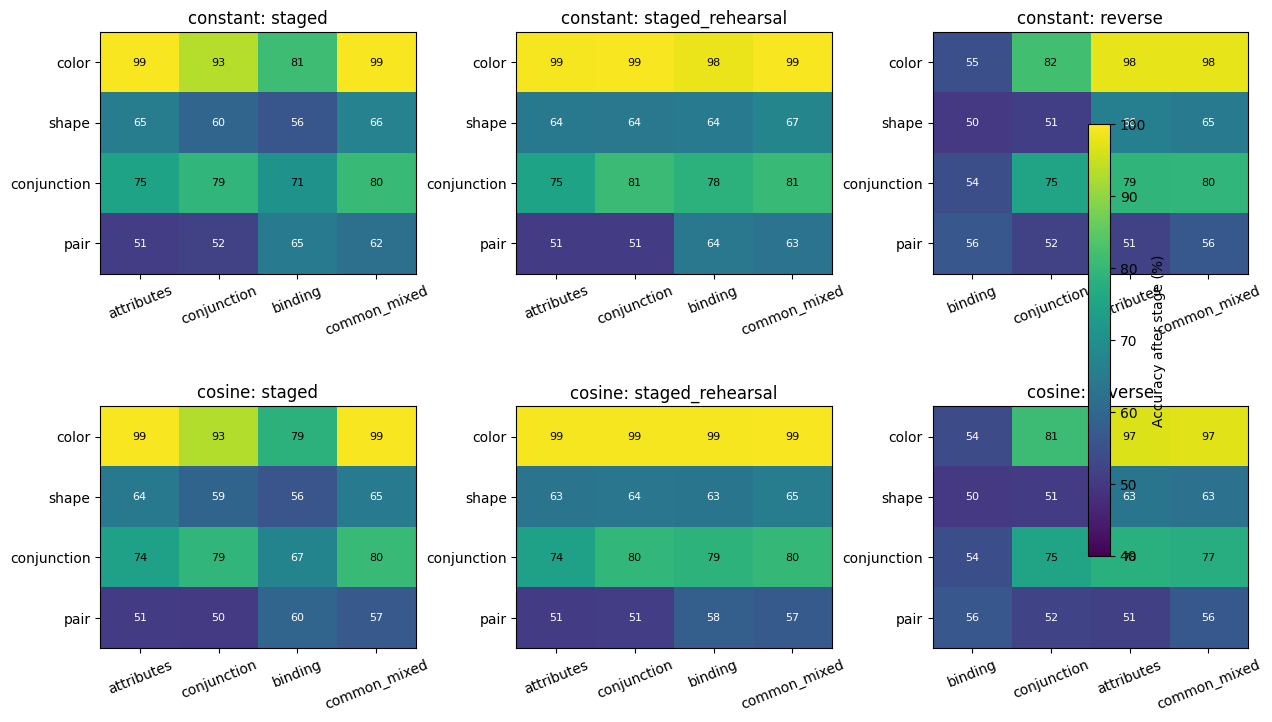

In [11]:
phase_rows = []
for lr_policy, rep in reports.items():
    for r in rep['runs']:
        points = {h['step']: h for h in r['history']}
        start = 0
        for item in r['phase_plan']['phases']:
            end = start + item['presentations'] // rep['config']['batch_size']
            observed_start = max(t for t in points if t <= start)
            observed_end = max(t for t in points if t <= end)
            for task in TASKS:
                a = 100 * points[observed_start]['id_dev']['by_template'][task]
                b = 100 * points[observed_end]['id_dev']['by_template'][task]
                phase_rows.append({'lr_policy': lr_policy, 'seed': r['seed'],
                                   'schedule': r['schedule'], 'phase': item['name'],
                                   'start': start, 'end': end, 'observed_end': observed_end,
                                   'task': task,
                                   'accuracy_end': b, 'change_pp': b - a})
            start = end
phase_scores = pd.DataFrame(phase_rows)
phase_scores.to_csv(OUTPUT_DIR / 'phase_skill_changes.csv', index=False)
display(phase_scores.groupby(['lr_policy', 'schedule', 'phase', 'task'])
        [['accuracy_end', 'change_pp']].mean().round(2))

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for i, lr_policy in enumerate(reports):
    for j, schedule in enumerate(('staged', 'staged_rehearsal', 'reverse')):
        frame = phase_scores[(phase_scores.lr_policy == lr_policy) &
                             (phase_scores.schedule == schedule)]
        phases = list(dict.fromkeys(frame[frame.seed == frame.seed.min()].phase))
        table = frame.groupby(['task', 'phase'])['accuracy_end'].mean().unstack('phase')
        table = table.reindex(index=TASKS, columns=phases)
        ax = axes[i, j]
        im = ax.imshow(table, cmap='viridis', vmin=40, vmax=100, aspect='auto')
        ax.set(title=f'{lr_policy}: {schedule}', xticks=range(len(phases)),
               xticklabels=phases, yticks=range(len(TASKS)), yticklabels=TASKS)
        ax.tick_params(axis='x', rotation=22)
        for y in range(len(TASKS)):
            for x in range(len(phases)):
                ax.text(x, y, f'{table.iloc[y,x]:.0f}', ha='center', va='center',
                        fontsize=8, color='white' if table.iloc[y,x] < 68 else 'black')
fig.colorbar(im, ax=axes.ravel().tolist(), label='Accuracy after stage (%)', shrink=.7)
fig.subplots_adjust(wspace=.32, hspace=.55, right=.89, bottom=.11)
save_figure(fig, 'long_budget_stage_skill_matrices')
plt.show()

## 8. Did early-stage learning persist or disappear?

For staged and staged-rehearsal, compare the last pre-binding checkpoint with the **worst** color/shape/conjunction accuracy during binding, its final stage value, and recovery after mixed consolidation. Unlike a single transition delta, this distinguishes short-lived interference from sustained forgetting.

first_100_pp  max_drop_pp  \
lr_policy schedule         task                                     
constant  staged           color               -6.17        15.47   
                           conjunction         -9.92        14.61   
                           shape               -4.92         7.19   
          staged_rehearsal color               -0.47         1.56   
                           conjunction         -4.30         4.61   
                           shape               -0.31         4.77   
cosine    staged           color               -6.72        16.56   
                           conjunction         -7.19        13.52   
                           shape               -3.20         5.31   
          staged_rehearsal color               -1.48         1.56   
                           conjunction         -5.62         5.62   
                           shape               -2.58         3.44   

                                        binding_stage_change  \
lr_policy schedule         task                                
constant  staged           color                      -11.95   
                           conjunction                 -8.67   
                           shape                       -3.52   
          staged_rehearsal color                       -1.02   
                           conjunction                 -2.42   
                           shape                        0.55   
cosine    staged           color                      -14.45   
                           conjunction                -12.34   
                           shape                       -3.67   
          staged_rehearsal color                        0.00   
                           conjunction                 -0.94   
                           shape                       -0.31   

                                        later_recovery_pp  
lr_policy schedule         task                            
constant  staged           color                    18.20  
                           conjunction               9.53  
                           shape                    10.47  
          staged_rehearsal color                     1.09  
                           conjunction               2.11  
                           shape                     2.73  
cosine    staged           color                    20.70  
                           conjunction              13.44  
                           shape                     8.98  
          staged_rehearsal color                     0.16  
                           conjunction               1.33  
                           shape                     1.88

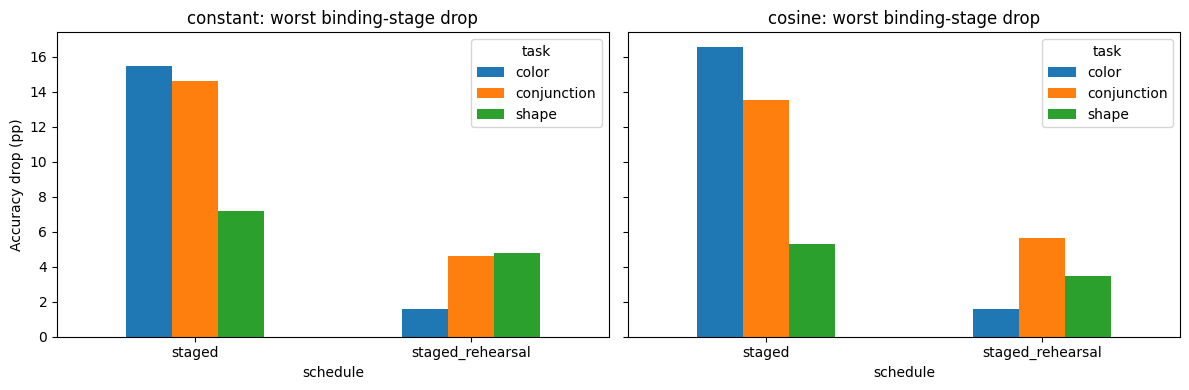

In [12]:
forget_rows = []
for lr_policy, rep in reports.items():
    for r in rep['runs']:
        if r['schedule'] not in ('staged', 'staged_rehearsal'):
            continue
        plan = r['phase_plan']['phases']
        idx = next(i for i, p in enumerate(plan) if p['name'] == 'binding')
        start = sum(p['presentations'] for p in plan[:idx]) // rep['config']['batch_size']
        end = start + plan[idx]['presentations'] // rep['config']['batch_size']
        snapshots = {h['step']: h for h in r['history']}
        pre_binding = max(t for t in snapshots if t <= start)
        observed_end = max(t for t in snapshots if t <= end)
        samples = [h for h in r['history'] if start < h['step'] <= end]
        for task in ('color', 'shape', 'conjunction'):
            baseline = 100 * snapshots[pre_binding]['id_dev']['by_template'][task]
            readings = [100 * h['id_dev']['by_template'][task] for h in samples]
            at_end = 100 * snapshots[observed_end]['id_dev']['by_template'][task]
            at_final = 100 * r['final']['id_dev']['by_template'][task]
            forget_rows.append({'lr_policy': lr_policy, 'schedule': r['schedule'],
                                'seed': r['seed'], 'task': task, 'binding_start': start,
                                'binding_end': end, 'first_100_pp': readings[0] - baseline,
                                'max_drop_pp': max(0, baseline - min(readings)),
                                'binding_stage_change': at_end - baseline,
                                'later_recovery_pp': at_final - at_end})
forgetting = pd.DataFrame(forget_rows)
forgetting.to_csv(OUTPUT_DIR / 'binding_forgetting_recovery.csv', index=False)
display(forgetting.groupby(['lr_policy', 'schedule', 'task'])
        [['first_100_pp', 'max_drop_pp', 'binding_stage_change', 'later_recovery_pp']]
        .mean().round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, lr_policy in zip(axes, reports):
    frame = forgetting[forgetting.lr_policy == lr_policy]
    pivot = frame.groupby(['schedule', 'task'])['max_drop_pp'].mean().unstack('task')
    pivot.reindex(('staged', 'staged_rehearsal')).plot.bar(ax=ax, rot=0)
    ax.set(title=f'{lr_policy}: worst binding-stage drop', ylabel='Accuracy drop (pp)')
plt.tight_layout()
save_figure(fig, 'worst_forgetting_by_lr_policy')
plt.show()

## 9. Learning efficiency per *binding example*

Global-update AULC favors schedules that introduce binding sooner. To examine transfer from prerequisites, plot binding accuracy against **estimated cumulative binding-question presentations**. Exposure is distributed uniformly within each recorded phase when exact within-phase order is unavailable. This is an exposure-aligned descriptive comparison, **not** a counterfactual equal-optimization experiment.

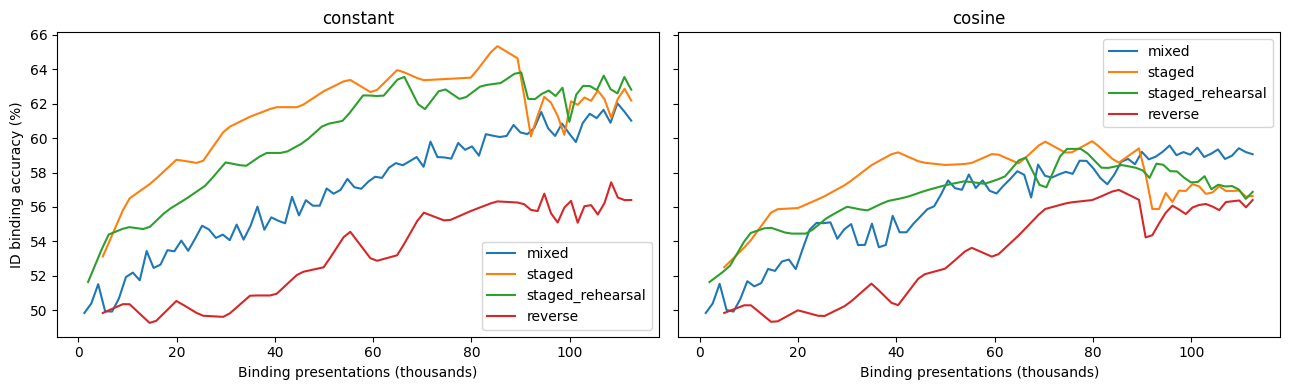

In [13]:
def binding_exposure_history(run, config):
    plan = run['phase_plan']['phases']
    allocations = {p['name']: p['by_template'].get('pair', 0)
                   for p in run['phase_plan'].get('phase_task_presentations', [])}
    spans = []
    start, exposed = 0, 0
    for p in plan:
        end = start + p['presentations'] // config['batch_size']
        pair_count = allocations.get(p['name'])
        if pair_count is None:
            fraction = .25 if p['name'] in ('mixed', 'common_mixed') else                        1.0 if p['name'] == 'binding' else 0.0
            pair_count = p['presentations'] * fraction
        spans.append((start, end, exposed, exposed + pair_count))
        exposed += pair_count
        start = end
    samples = []
    for h in run['history']:
        step = h['step']
        seg = next(s for s in spans if s[0] <= step <= s[1])
        count = seg[2] + (seg[3] - seg[2]) * (step - seg[0]) / (seg[1] - seg[0])
        if count > 0:
            samples.append((count, 100 * h['id_dev']['by_template']['pair']))
    return pd.DataFrame(samples, columns=['binding_presentations', 'accuracy'])

exposed = []
for lr_policy, rep in reports.items():
    for r in rep['runs']:
        h = binding_exposure_history(r, rep['config'])
        h['lr_policy'], h['seed'], h['schedule'] = lr_policy, r['seed'], r['schedule']
        exposed.append(h)
exposed = pd.concat(exposed, ignore_index=True)
exposed.to_csv(OUTPUT_DIR / 'binding_exposure_aligned_curves.csv', index=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, lr_policy in zip(axes, reports):
    for schedule in SCHEDULES:
        series = []
        for seed in sorted(exposed.seed.unique()):
            data = exposed[(exposed.lr_policy == lr_policy) &
                           (exposed.schedule == schedule) & (exposed.seed == seed)]
            x = data.binding_presentations.to_numpy()
            y = data.accuracy.to_numpy()
            x_unique, indices = np.unique(x, return_index=True)
            series.append((x_unique, y[indices]))
        lo = max(x[0] for x, _ in series)
        hi = min(x[-1] for x, _ in series)
        grid = np.linspace(lo, hi, 80)
        mean = np.mean([np.interp(grid, x, y) for x, y in series], axis=0)
        ax.plot(grid / 1000, mean, label=schedule)
    ax.set(title=lr_policy, xlabel='Binding presentations (thousands)')
    ax.legend()
axes[0].set_ylabel('ID binding accuracy (%)')
plt.tight_layout()
save_figure(fig, 'binding_accuracy_per_binding_exposure')
plt.show()

## 10. OOD predictions: accuracy versus BCE over training

An OOD accuracy above 50% does not guarantee useful confidence estimates. Mean OOD binary cross-entropy can exceed \(-\log(0.5)\) even when accuracy improves, indicating unfavorable probability assignments under log loss. The histories contain aggregate BCE, **not** individual logits, so this does not identify which errors are overconfident.

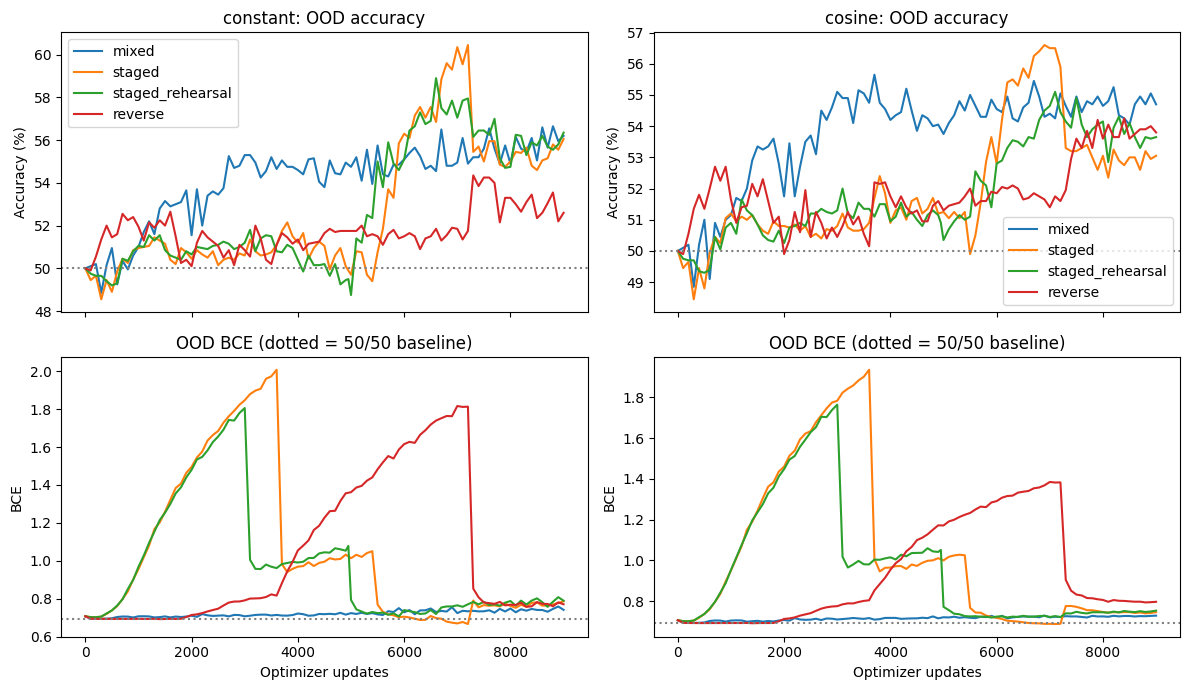

In [14]:
ood = pd.DataFrame([{
    'lr_policy': name, 'seed': r['seed'], 'schedule': r['schedule'],
    'step': h['step'], 'ood_accuracy': 100 * h['ood_dev']['by_template']['pair'],
    'ood_bce': h['ood_dev']['loss']
} for name, rep in reports.items() for r in rep['runs'] for h in r['history']])
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex='col')
for col, lr_policy in enumerate(reports):
    for schedule in SCHEDULES:
        data = ood[(ood.lr_policy == lr_policy) & (ood.schedule == schedule)]
        group = data.groupby('step')[['ood_accuracy', 'ood_bce']].mean()
        axes[0, col].plot(group.index, group.ood_accuracy, label=schedule)
        axes[1, col].plot(group.index, group.ood_bce, label=schedule)
    axes[0, col].set(title=f'{lr_policy}: OOD accuracy', ylabel='Accuracy (%)')
    axes[0, col].axhline(50, linestyle=':', color='gray')
    axes[1, col].axhline(np.log(2), linestyle=':', color='gray')
    axes[1, col].set(title='OOD BCE (dotted = 50/50 baseline)',
                     xlabel='Optimizer updates', ylabel='BCE')
    axes[0, col].legend()
plt.tight_layout()
save_figure(fig, 'ood_accuracy_and_bce_trajectories')
plt.show()

## How to interpret this phase

Distinguish **final binding**, **learning efficiency**, and **OOD generalization**. If the curriculum ranking changes between constant and cosine LR, the optimizer interacts with task order. It does not yet establish that the ViT learned reusable object-level representations. The OOD development set was investigated repeatedly and is not a final, independent test.